In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')
sys.path.insert(0, os.getcwd())
try:
    from 集成公共函数 import *
except ImportError as e:
    print('导入 集成公共函数.py 失败:', e)
    print('请确认Jupyter内核的工作目录为「实验室」文件夹(该文件与本notebook同目录)。')
    raise
 
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import joblib
import shap
from IPython.display import display


OUT_DIR   = SHAP_DIR
ARTIFACT  = ARTIFACT_PATH

COMP_XLSX = EXT_PRED_CMP_PATH  
print('模块二结果路径 COMP_XLSX =', COMP_XLSX, '| 存在:', os.path.exists(COMP_XLSX))



TAG_EN   = {'TS': 'Tensile strength', 'TM': 'Tensile modulus',
            'FS': 'Flexural strength', 'FM': 'Flexural modulus', 'IS': 'Impact strength'}
FEAT_EN  = {'T_noz': 'Extrusion Temperature (°C)', 'T_bed': 'Bed Temperature (°C)',
            'speed': 'Print Speed (mm·s\u207B\u00B9)', 'layer': 'Layer Height (mm)',
            'direction': 'Build Orientation'}


# 风格与配色
STYLE_NAME = "science"          
CMAP_NAME  = "viridis"          
BAR_SCHEME = "okabe_ito"   
SAVE_DPI   = 600

BASE_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Times New Roman"],
    "font.serif": ["Times New Roman",],
    "mathtext.fontset": "stixsans",
    "font.size": 9.0,
    "axes.labelsize": 9.5,
    "axes.titlesize": 10.0,
    "xtick.labelsize": 8.2,
    "ytick.labelsize": 8.2,
    "legend.fontsize": 8.0,
    "axes.linewidth": 0.8,
    "axes.edgecolor": "#333333",
    "axes.labelweight": "normal",
    "axes.titleweight": "normal",
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.major.size": 3.4,
    "ytick.major.size": 3.4,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.top": False,
    "ytick.right": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#D9D9D9",
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
    "grid.alpha": 0.55,
    "axes.unicode_minus": False,
    "figure.dpi": 800,
    "savefig.dpi": SAVE_DPI,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "savefig.facecolor": "white",
    "legend.frameon": False,
    "legend.framealpha": 0.95,
    "legend.edgecolor": "#B8B8B8",
    "legend.fancybox": False,
    "lines.linewidth": 1.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

STYLES = {
    "science": {
        "font.family": "sans-serif", "font.sans-serif": ["Times New Roman", "DejaVu Sans"],
        "mathtext.fontset": "stixsans",
        "font.size": 9.0, "axes.labelsize": 9.5, "axes.titlesize": 10.0,
        "xtick.labelsize": 8.2, "ytick.labelsize": 8.2, "legend.fontsize": 8.0,
        "axes.linewidth": 0.8, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
        "xtick.major.size": 3.4, "ytick.major.size": 3.4,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.top": False, "ytick.right": False,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.50,
        "axes.labelweight": "normal", "axes.titleweight": "normal",
    }
}

CMAPS = {
    "viridis": "viridis", "cividis": "cividis", "coolwarm": "coolwarm",
}
BAR_SCHEMES = {
    "okabe_ito": ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"],
}



def apply_style(style_name=STYLE_NAME, cmap_name=CMAP_NAME, bar_scheme=BAR_SCHEME):
    if style_name not in STYLES:
        raise ValueError(f"未知 STYLE_NAME={style_name!r}，可选：{list(STYLES)}")
    if cmap_name not in CMAPS:
        raise ValueError(f"未知 CMAP_NAME={cmap_name!r}，可选：{list(CMAPS)}")
    if bar_scheme not in BAR_SCHEMES:
        raise ValueError(f"未知 BAR_SCHEME={bar_scheme!r}，可选：{list(BAR_SCHEMES)}")
    mpl.rcParams.update(BASE_RC)
    mpl.rcParams.update(STYLES[style_name])
    mpl.rcParams["savefig.dpi"] = SAVE_DPI
    return CMAPS[cmap_name], BAR_SCHEMES[bar_scheme]


CMAP, BAR_COLORS = apply_style()

print('shap version:', shap.__version__)

模块二结果路径 COMP_XLSX = d:\Code_File\Python_Data_AI\Project_CFPA_Teacher\Data\外部验证\外部验证预测结果.xlsx | 存在: True
shap version: 0.50.0


In [2]:
ART = load_or_build_models()     
ENSEMBLES     = ART['ENSEMBLES']
TUNED         = ART['TUNED']
W_raw         = ART['W_raw']
WEIGHTS_TABLE = ART['WEIGHTS_TABLE']
CV_SCORES     = ART['CV_SCORES']
BEST_PARAMS   = ART['BEST_PARAMS']
TUNE_META     = ART['TUNE_META']


_MEMBER_NAMES = list(base_learners().keys())
BEST_SINGLE, MAXW_SINGLE = {}, {}
for tag in SHEETS.values():
    b, mw = best_and_maxw_single(tag, CV_SCORES[tag], W_raw[tag], names=_MEMBER_NAMES)
    BEST_SINGLE[tag] = ART.get('BEST_SINGLE', {}).get(tag, b)
    MAXW_SINGLE[tag] = ART.get('MAXW_SINGLE', {}).get(tag, mw)
print('CV最优单一模型  :', BEST_SINGLE)
print('权重最大单一模型:', MAXW_SINGLE)


[加载] 已从存档载入集成模型: d:\Code_File\Python_Data_AI\Project_CFPA_Teacher\Data\集成建模\集成模型存档.joblib (version=3)
CV最优单一模型  : {'TS': 'GBoost', 'TM': 'GBoost', 'FS': 'GBM', 'FM': 'GBoost', 'IS': 'RF'}
权重最大单一模型: {'TS': 'GBoost', 'TM': 'GBoost', 'FS': 'GBM', 'FM': 'GBoost', 'IS': 'RF'}


In [ ]:
#shap解释  shap.explainers.Exact
# 解释对象是整个加权集成的预测函数
CACHE_PATH = os.path.join(OUT_DIR, 'shap_cache_ensemble.joblib')
CACHE = joblib.load(CACHE_PATH) if os.path.exists(CACHE_PATH) else {}

SV, SVI, XS, YS = {}, {}, {}, {}
for tag in SHEETS.values():
    d = load_long(TAG2SHEET[tag])
    X = d[FEATS].astype(float).reset_index(drop=True)
    y = d['y'].values.astype(float)

    if tag in CACHE and all(k in CACHE[tag] for k in ('sv', 'svi', 'X', 'y')):
        SV[tag] = CACHE[tag]['sv']
        SVI[tag] = CACHE[tag]['svi']
        XS[tag] = CACHE[tag]['X']
        YS[tag] = CACHE[tag]['y']
        print(f'{tag}: 读取缓存 ({len(X)} 个训练试样)')
    else:
        masker = shap.maskers.Independent(X, max_samples=50)
        ex = shap.explainers.Exact(ENSEMBLES[tag].predict, masker)
        t0 = time.time()
        SV[tag] = ex(X, silent=True)
        SVI[tag] = ex(X, interactions=True, silent=True)
        XS[tag], YS[tag] = X, y
        CACHE[tag] = dict(sv=SV[tag], svi=SVI[tag], X=X, y=y)
        joblib.dump(CACHE, CACHE_PATH, compress=3)
        print(f'{tag}:  SHAP 计算完成 ({time.time()-t0:.1f}s)')

TS: 读取缓存 (186 个训练试样)
TM: 读取缓存 (186 个训练试样)
FS: 读取缓存 (186 个训练试样)
FM: 读取缓存 (186 个训练试样)
IS: 读取缓存 (186 个训练试样)


##### 全局解释
- **(a) beeswarm**：每行一个特征（按平均 |SHAP| 从高到低），每个点 = 一个试样；横轴 = 该特征把预测推高（正）/拉低（负）多少，颜色 = 特征取值高低
- **(b) 平均 |SHAP| 重要性**：横向柱状图，特征顺序与左图一致，柱端标注数值

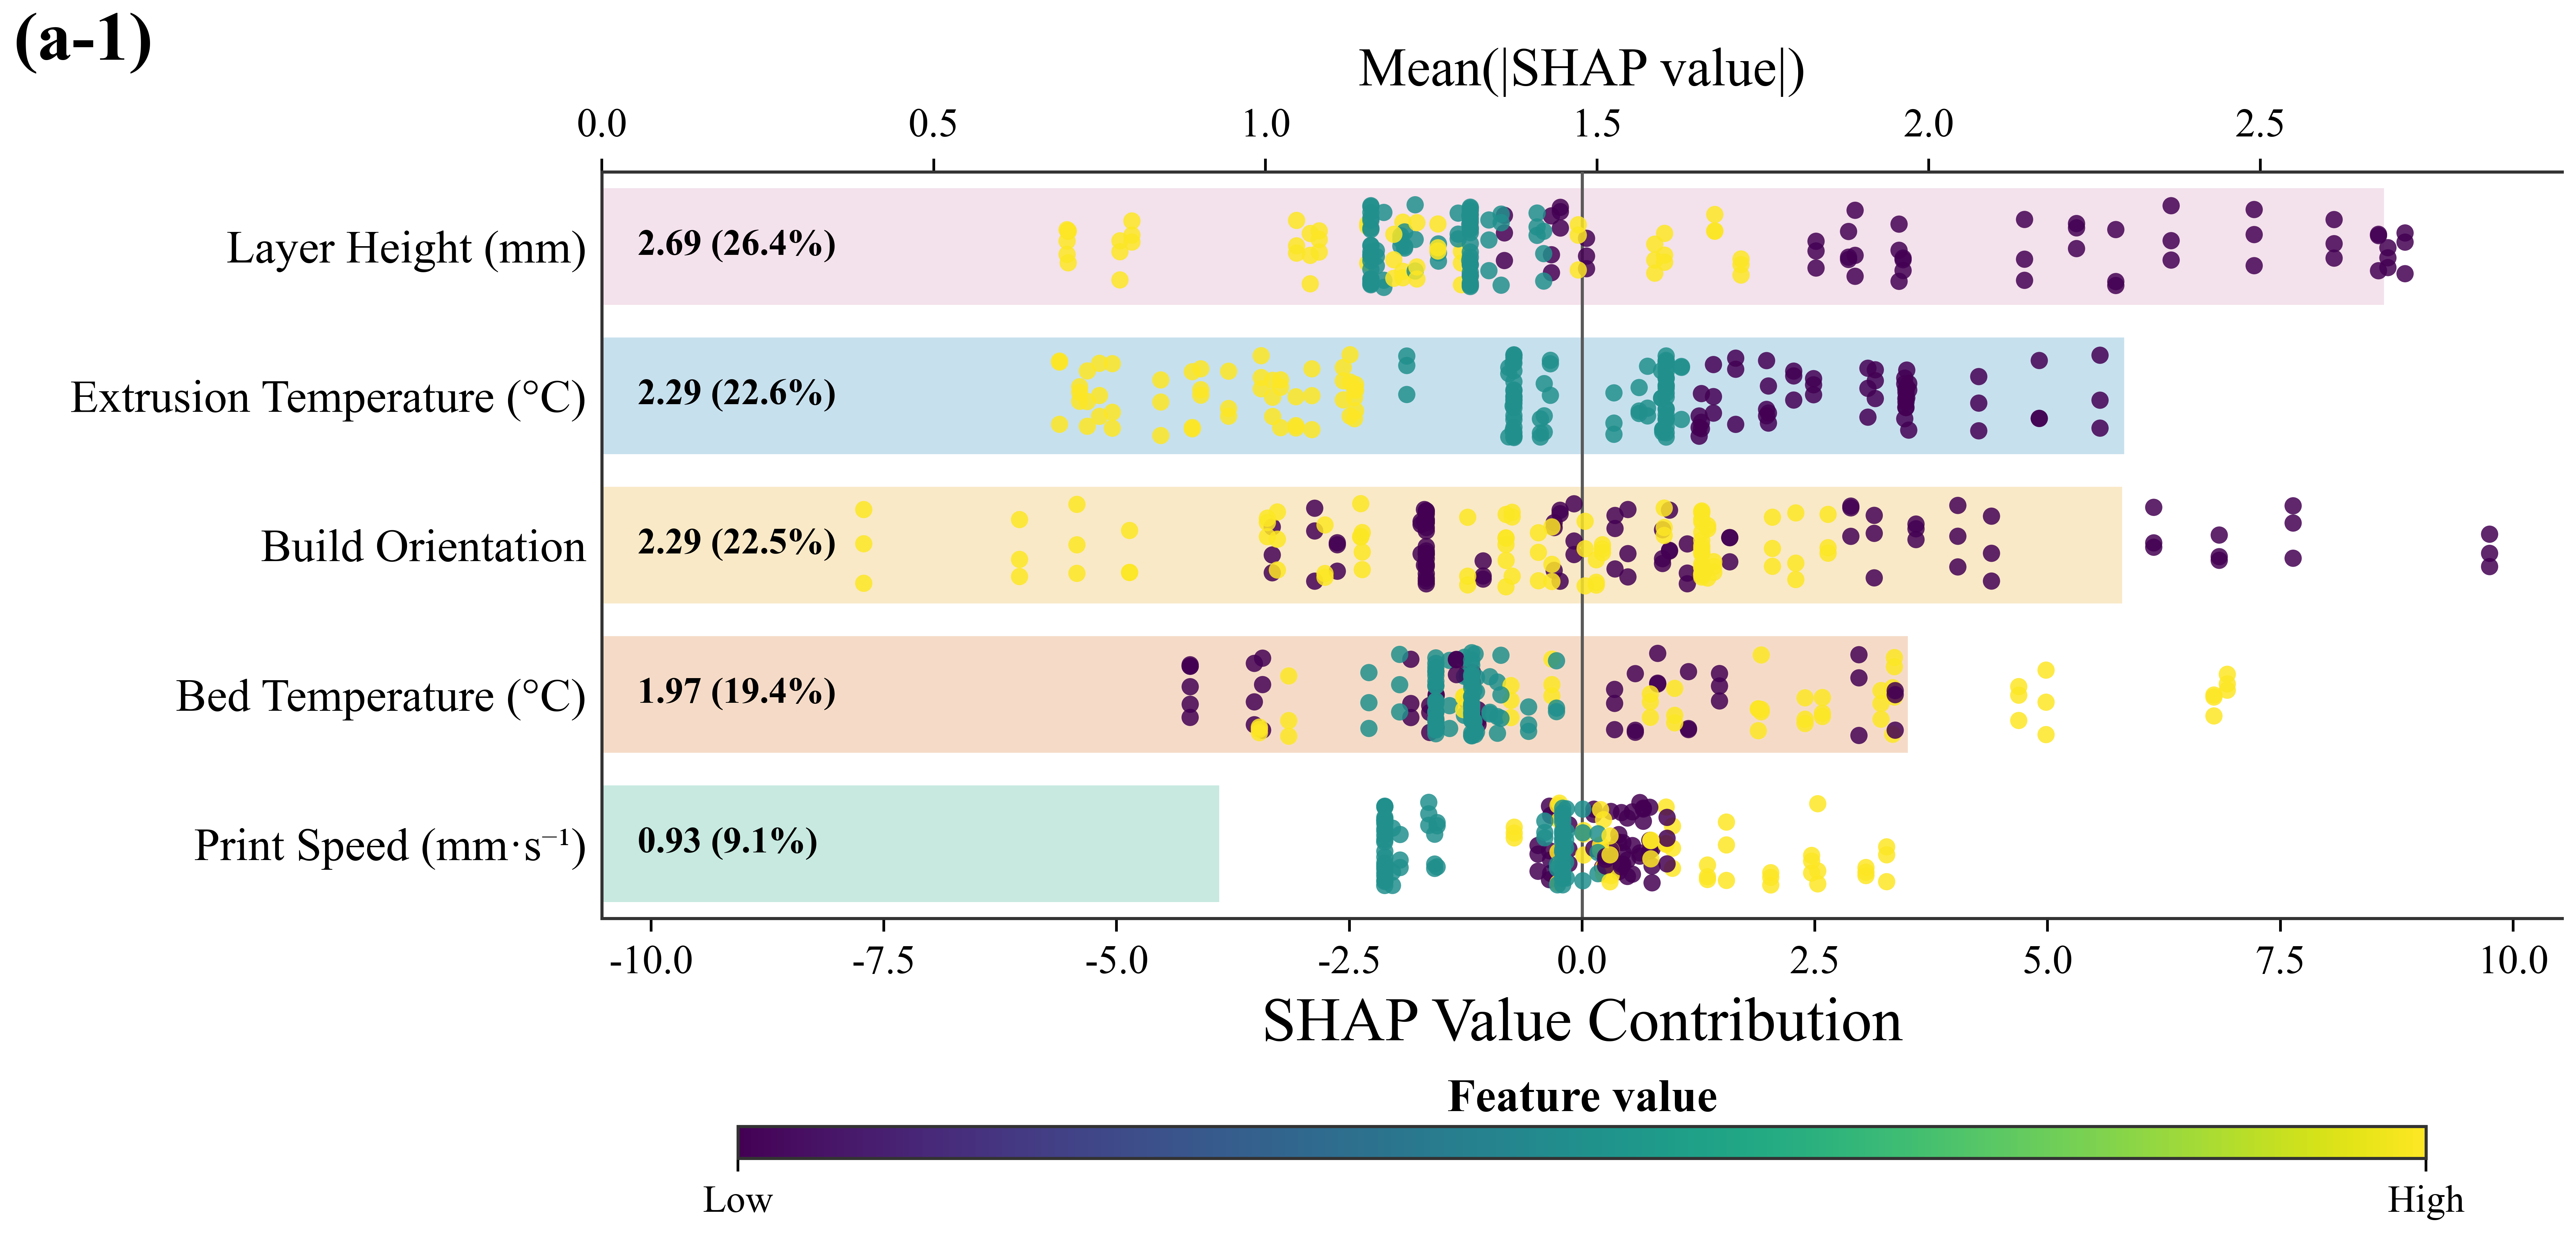

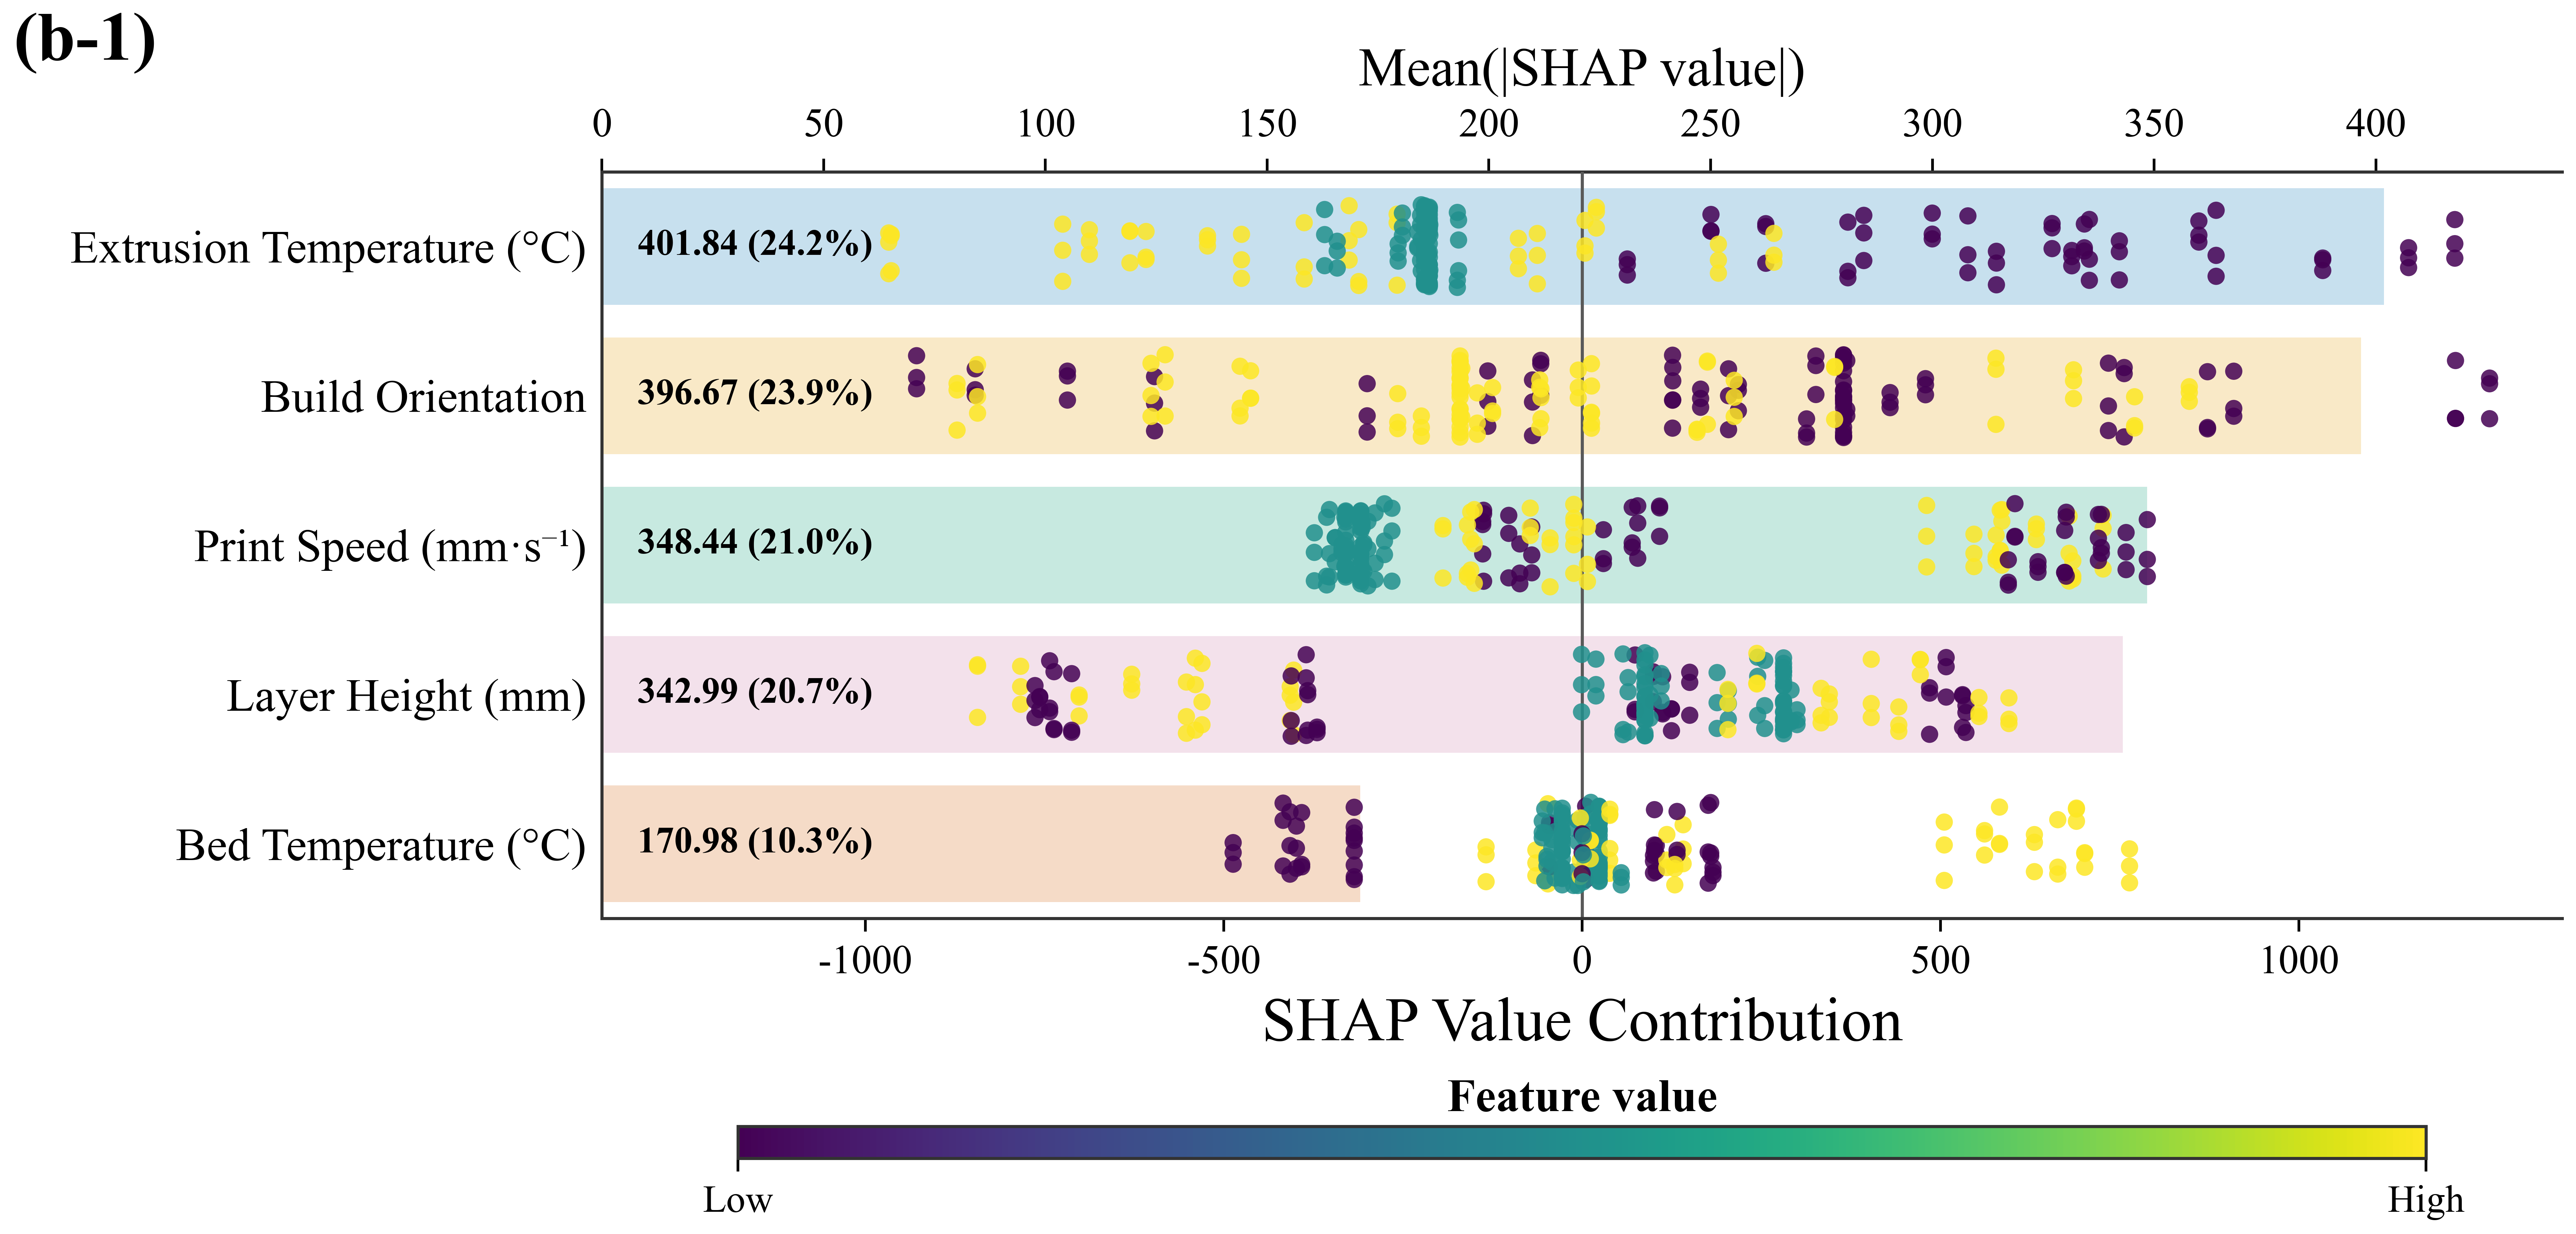

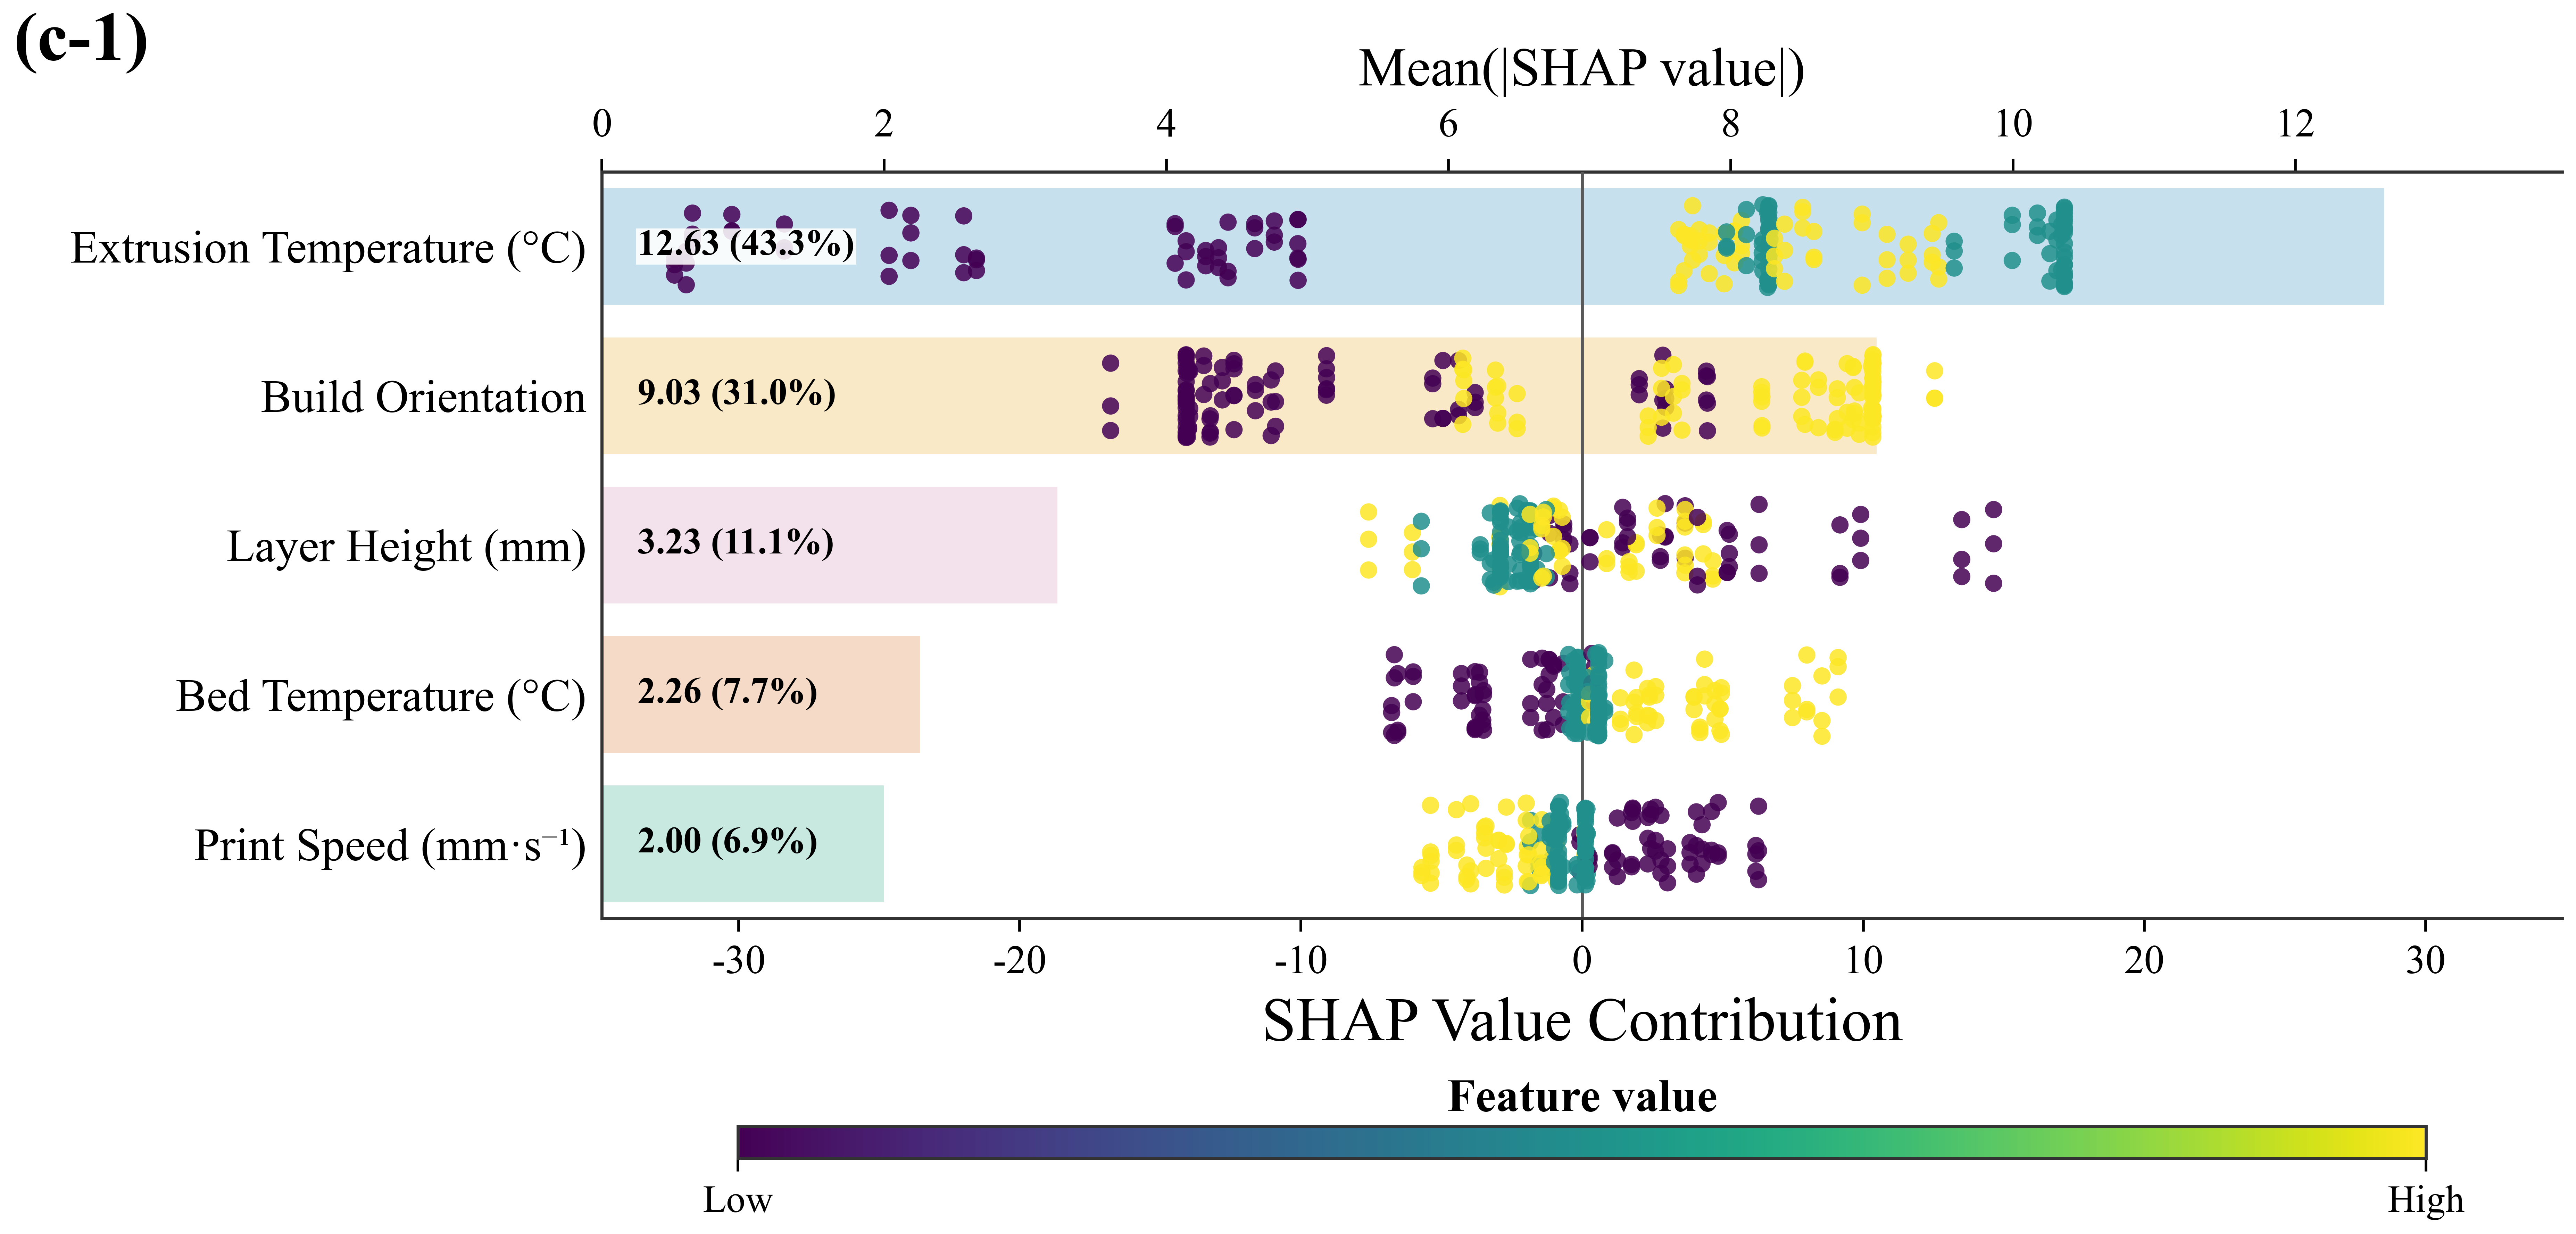

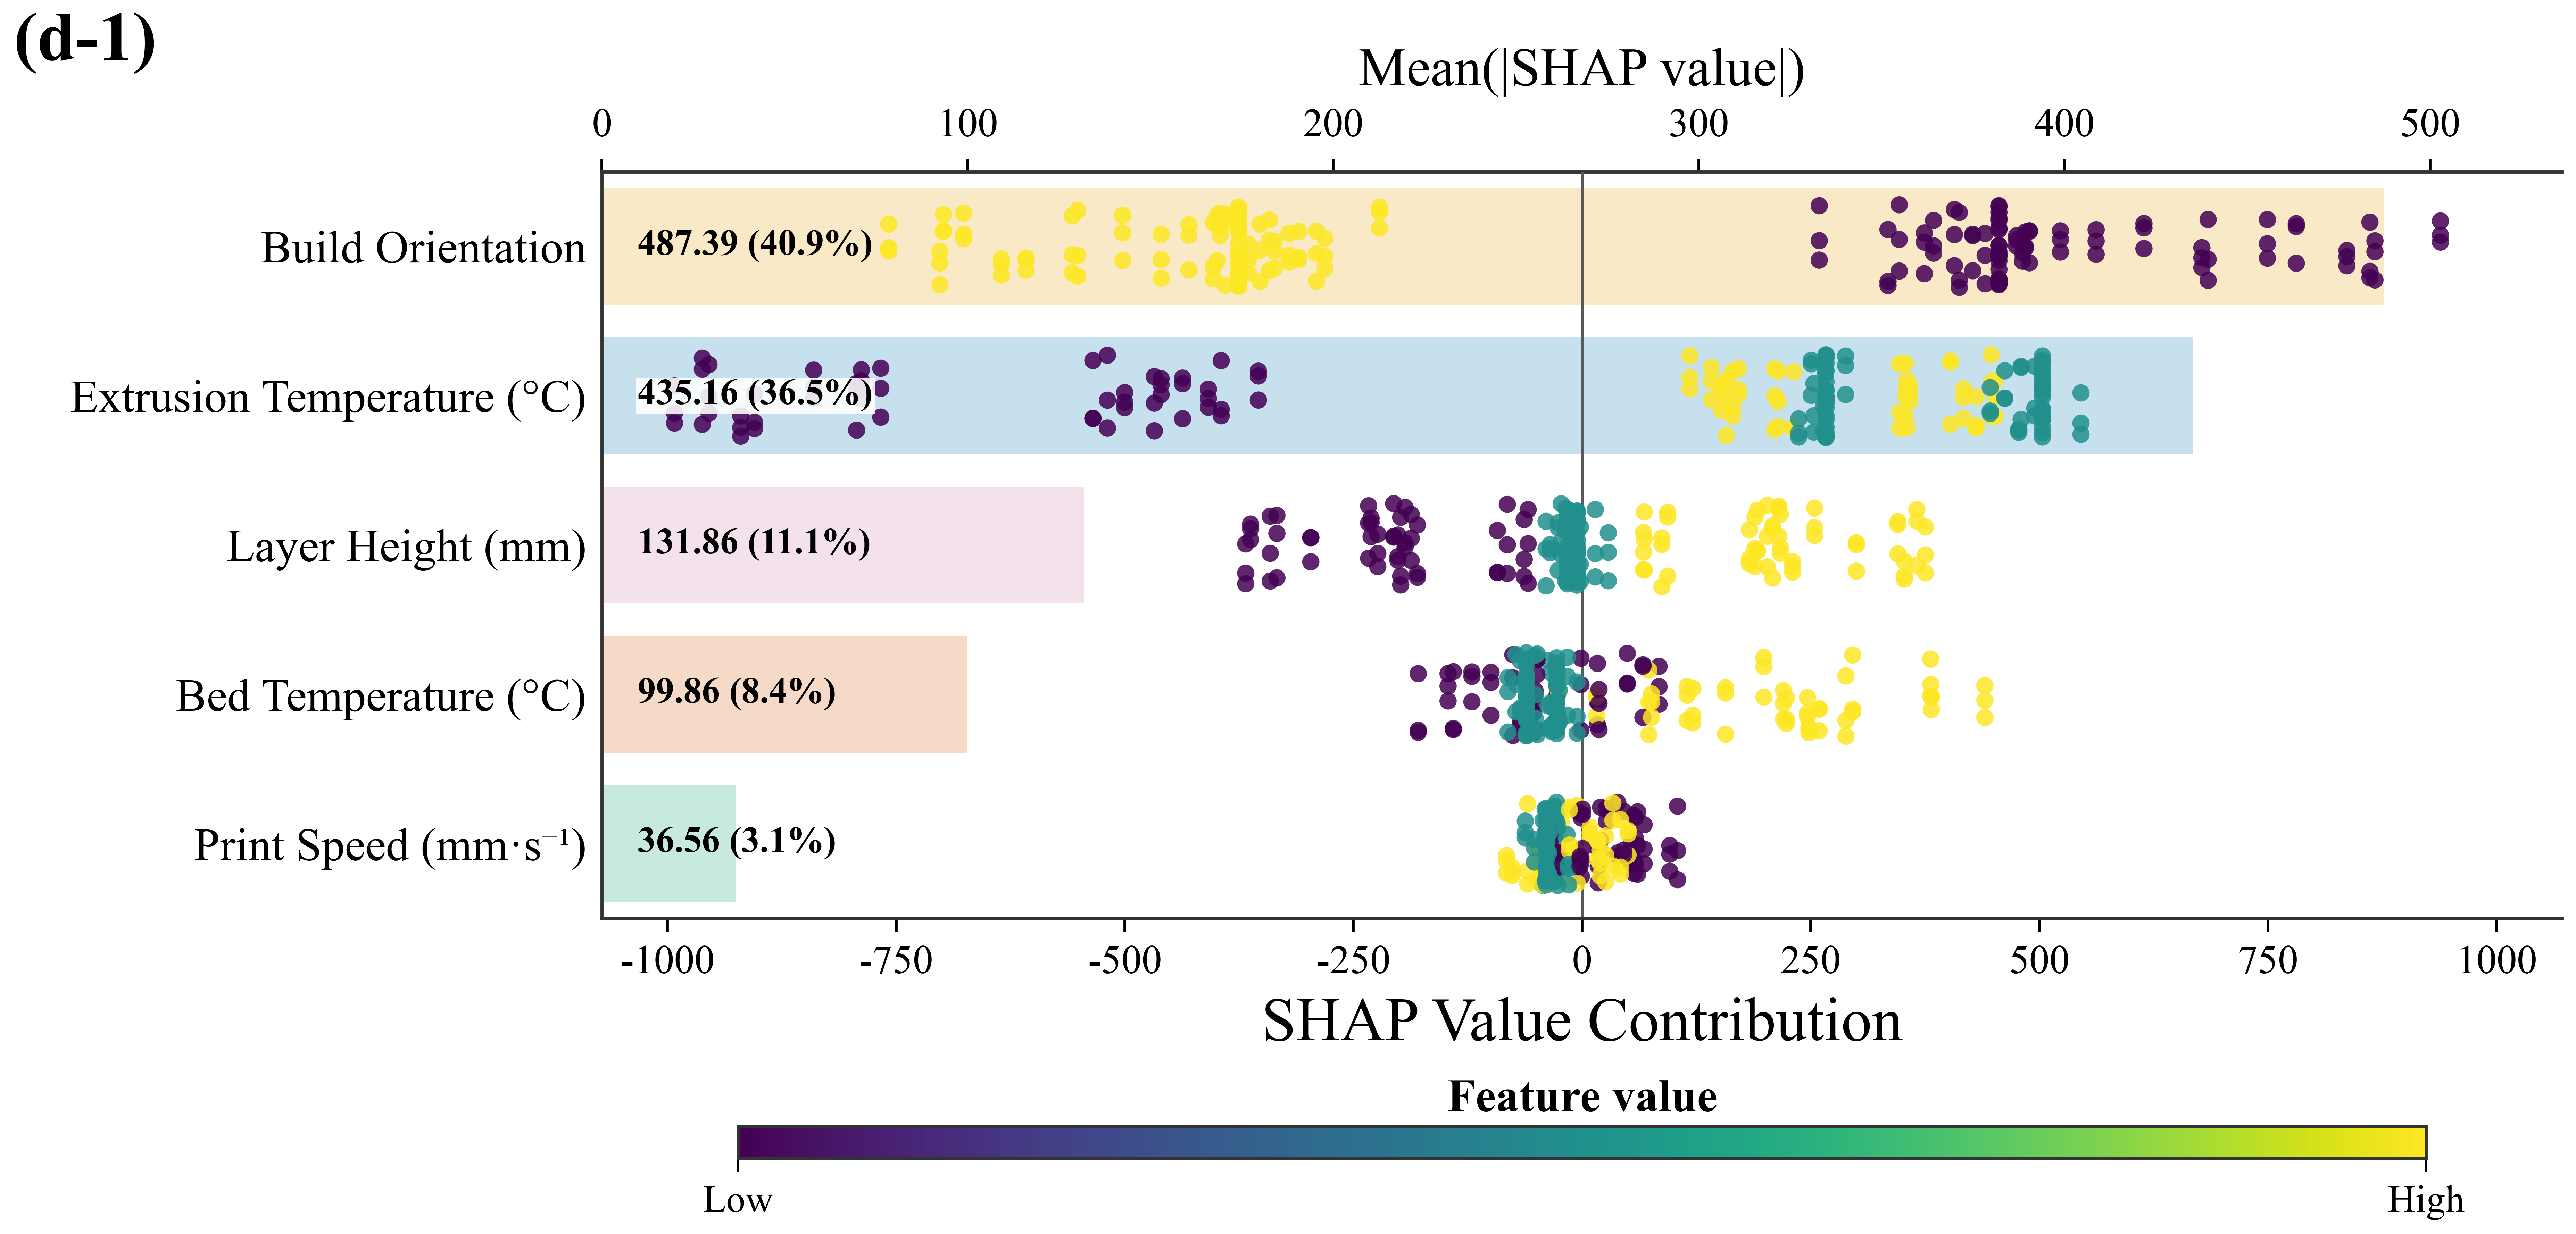

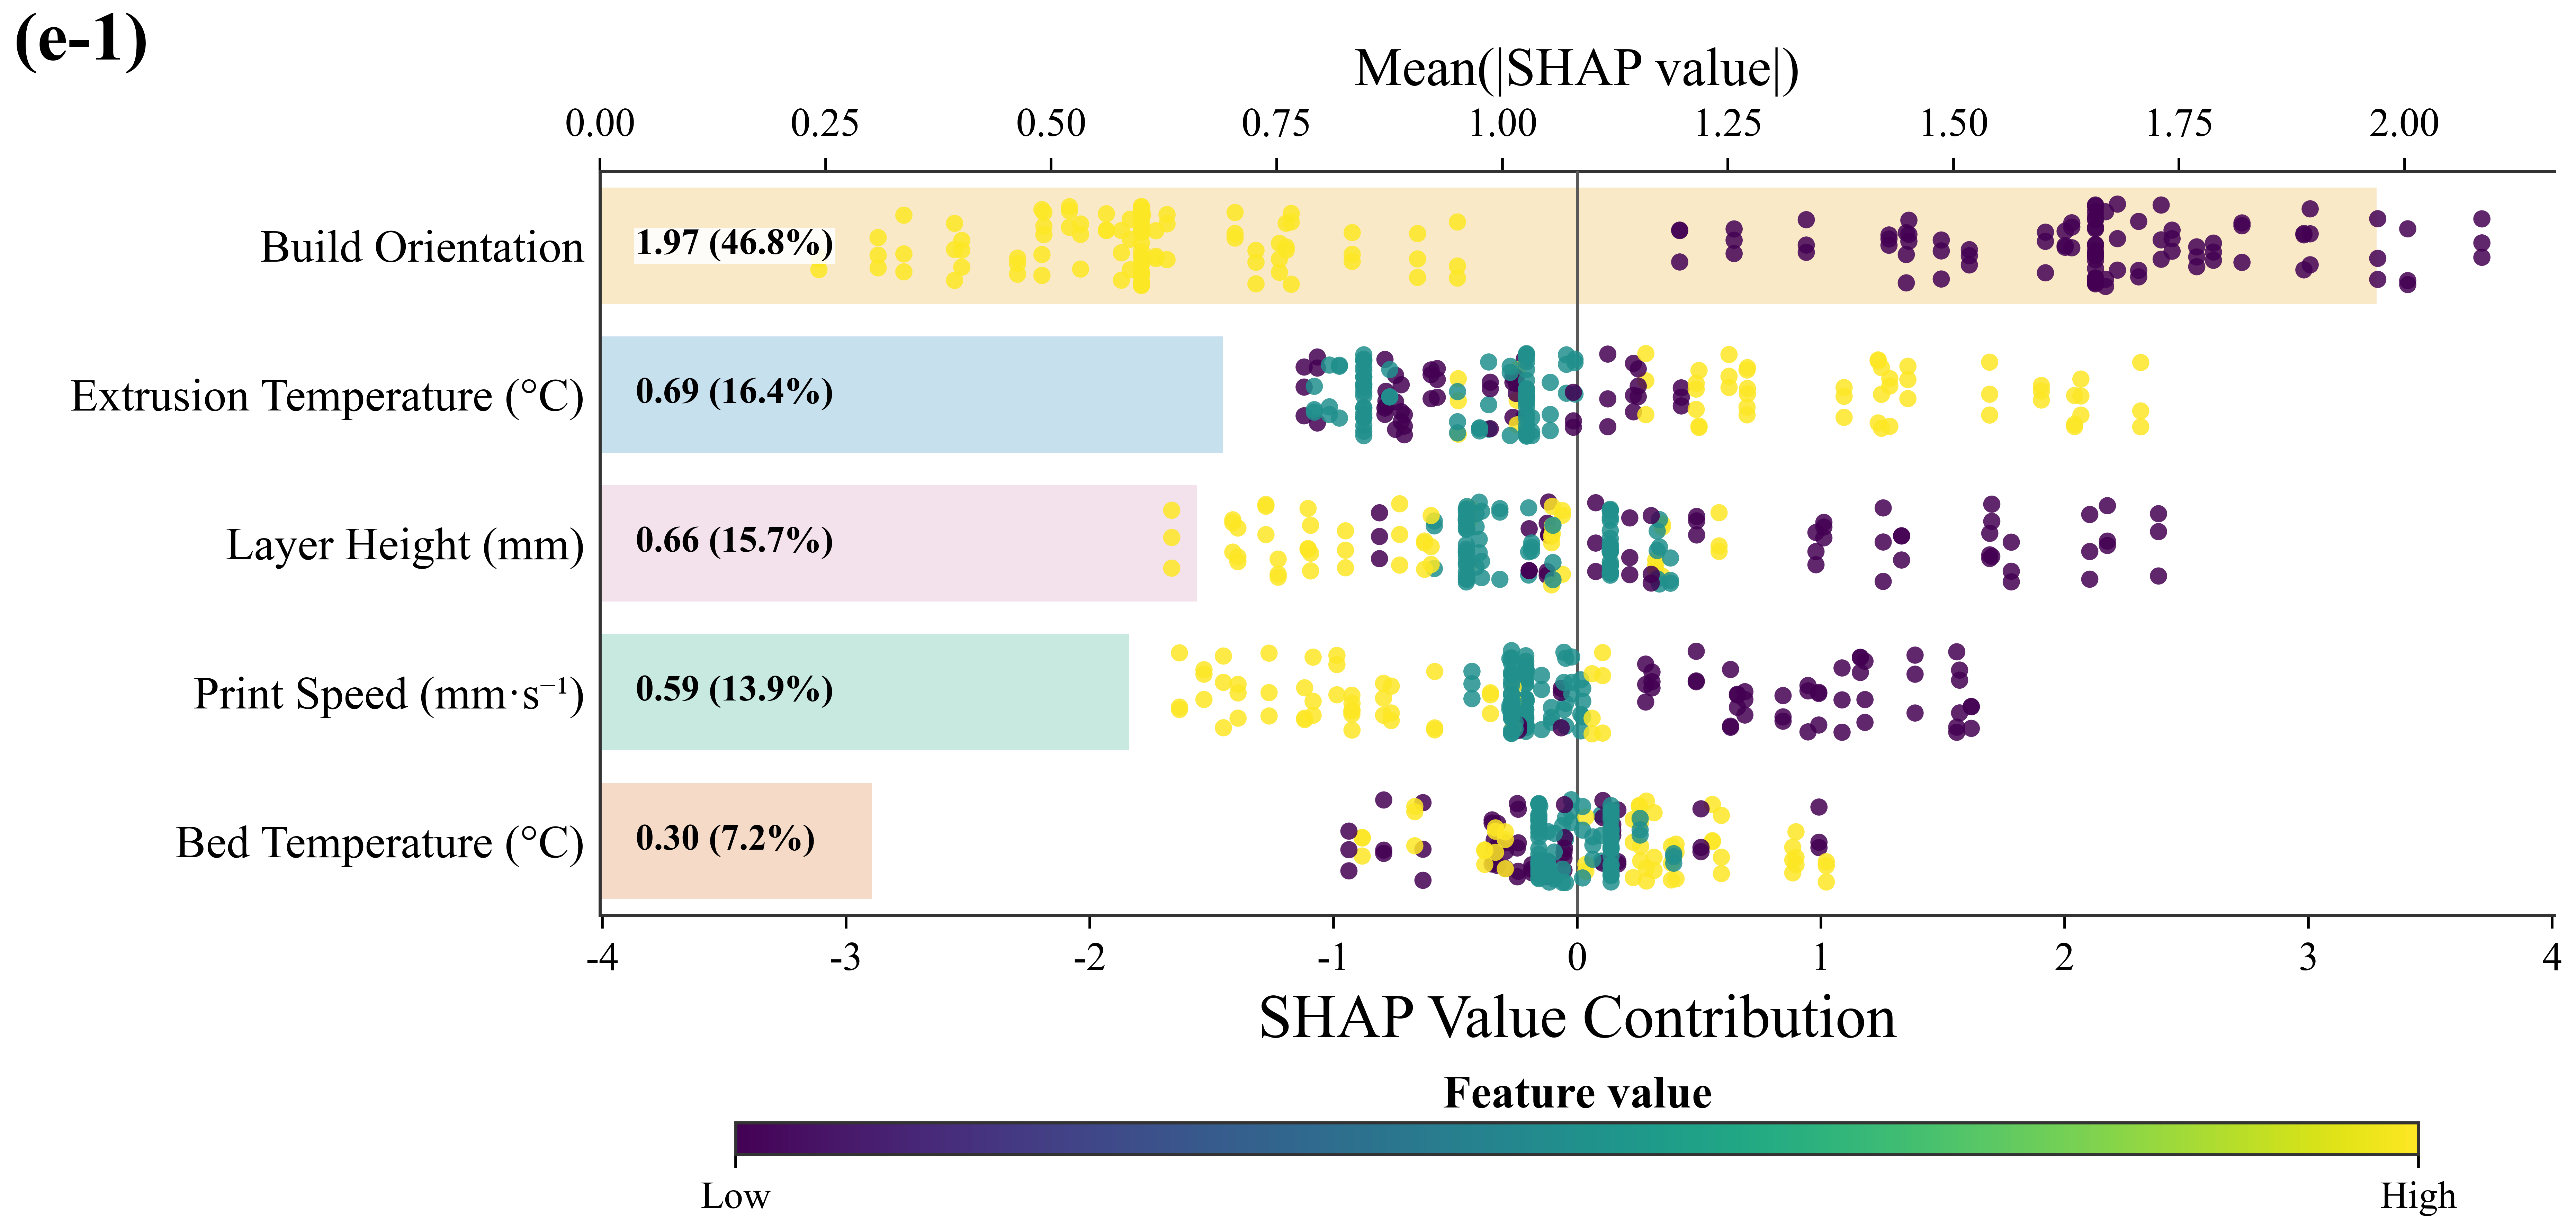

In [ ]:
FEAT_COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]

def plot_beeswarm(sv, X, ax, cmap):
    vals = np.asarray(sv.values, float)
    feat = X[FEATS].values.astype(float)
    n, p = feat.shape
    imp = np.abs(vals).mean(axis=0)
    order_f = np.argsort(imp)[::-1]
    rng = np.random.default_rng(2026)

    for rank, i in enumerate(order_f):
        fv = feat[:, i]
        z = (fv - fv.min()) / (np.ptp(fv) + 1e-12)
        y = np.full(n, rank) + rng.uniform(-0.28, 0.28, n)
        ax.scatter(vals[:, i], y, c=z, cmap=cmap, norm=Normalize(0, 1),
                   s=20, alpha=0.85, linewidths=0, rasterized=True, zorder=2)

    ax.axvline(0, color='0.35', lw=0.8, zorder=1)
    ax.set_yticks(range(p))
    ax.set_yticklabels([FEAT_EN[FEATS[i]] for i in order_f], fontsize=12)
    ax.set_ylim(p - 0.5, -0.5)
    ax.set_xlabel('SHAP Value Contribution', fontsize=16)
    ax.tick_params(axis='x', labelsize=10.5)
    ax.tick_params(axis='y', length=0, pad=4)
    ax.grid(False)
    return order_f

def plot_global_shap(tag, save_name, panel_label='(a-1)'):
    sv, X = SV[tag], XS[tag]
    vals = np.asarray(sv.values, float)
    mean_abs = np.abs(vals).mean(axis=0)
    shares = 100.0 * mean_abs / mean_abs.sum()

    fig, ax = plt.subplots(figsize=(9.8, 4.8))
    ax_bar = ax.twiny()
    ax_bar.set_zorder(0)
    ax.set_zorder(1)
    ax.patch.set_visible(False)
    ax_bar.patch.set_visible(False)

    order = plot_beeswarm(sv, X, ax, CMAP)

    for rank, i in enumerate(order):
        ax_bar.barh(rank, mean_abs[i], height=0.78,
                    color=mpl.colors.to_rgba(FEAT_COLORS[i], 0.22),
                    edgecolor="none", linewidth=0, zorder=0)
    ax_bar.set_xlim(0, mean_abs.max() * 1.10)
    ax_bar.set_ylim(len(order) - 0.5, -0.5)
    ax_bar.xaxis.set_ticks_position('top')
    ax_bar.xaxis.set_label_position('top')
    ax_bar.tick_params(axis='x', top=True, labeltop=True, bottom=False,
                       labelbottom=False, labelsize=10.5,
                       width=0.7, length=3.4)
    ax_bar.set_xlabel('Mean(|SHAP value|)', fontsize=14, labelpad=6)
    ax_bar.spines['top'].set_visible(True)
    ax_bar.spines['top'].set_linewidth(0.8)
    ax_bar.spines['bottom'].set_visible(False)
    ax_bar.spines['left'].set_visible(False)
    ax_bar.spines['right'].set_visible(False)

    texts = []
    for rank, i in enumerate(order):
        txt = ax.text(0.02 * mean_abs.max(), rank,
                      f'{mean_abs[i]:.2f} ({shares[i]:.1f}%)',
                      transform=ax_bar.transData, ha='left', va='center',
                      fontsize=9.5, color='black', fontweight='bold', zorder=10)
        texts.append((txt, i, rank))

    lim = max(abs(float(vals.min())), abs(float(vals.max()))) * 1.08
    ax.set_xlim(-lim, lim)

    sm = ScalarMappable(norm=Normalize(0, 1), cmap=CMAP)
    sm.set_array([])
    cax = fig.add_axes([0.27, 0.06, 0.62, 0.024])
    cbar = fig.colorbar(sm, cax=cax, orientation='horizontal')
    cbar.set_label('Feature value', fontsize=12, fontweight='bold', labelpad=4)
    cbar.ax.xaxis.set_label_position('top')
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(['Low', 'High'])
    cbar.ax.tick_params(labelsize=10)

    ax.text(-0.30, 1.13, panel_label, transform=ax.transAxes,
            ha='left', va='bottom', fontsize=18, fontweight='bold', clip_on=False)
    fig.subplots_adjust(top=0.80, bottom=0.24, left=0.22, right=0.94)

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for txt, i, rank in texts:
        bb = txt.get_window_extent(renderer)
        px = ax.transData.transform(np.column_stack([vals[:, i], np.full(len(vals), rank)]))[:, 0]
        if np.any((px >= bb.x0) & (px <= bb.x1)):
            txt.set_bbox(dict(facecolor='white', edgecolor='none', alpha=0.88, pad=0.45))

    fig.savefig(os.path.join(OUT_DIR, save_name), dpi=SAVE_DPI)
    plt.show()



for k, tag in enumerate(SHEETS.values()):
    plot_global_shap(tag, f'shap_全局_{tag}.png', panel_label=f'({chr(97 + k)}-1)')